# Weather Type Classification

Pipeline: EDA → **train/test split** → cleaning (dedup, missing values, outliers) fit only on the training fold → encoding/scaling fit only on train → BorderlineSMOTE (train only) → feature selection (train only) → model training/evaluation.


In [2]:
import pandas as pd 
import numpy as np

In [3]:
df=pd.read_csv("Weather_classification_data.csv")

In [4]:
df

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,18.0,58,10.0,28.0,partly cloudy,1017.27,4.0,Summer,8.0,coastal,Cloudy
1,32.0,57,10.0,46.0,overcast,1011.05,3.0,Autumn,5.5,inland,Cloudy
2,21.0,73,11.5,85.0,overcast,1006.09,2.0,Spring,5.5,inland,Rainy
3,11.0,77,13.0,21.0,partly cloudy,1003.85,4.0,Spring,5.0,coastal,Cloudy
4,28.0,84,37.5,105.0,partly cloudy,1018.64,5.0,Spring,2.0,inland,Rainy
...,...,...,...,...,...,...,...,...,...,...,...
8495,32.0,39,7.5,3.0,clear,1021.43,9.0,Autumn,5.5,inland,Sunny
8496,42.0,33,5.5,19.0,partly cloudy,1028.78,8.0,Spring,6.5,inland,Sunny
8497,19.0,63,15.0,15.0,overcast,1012.77,2.0,Winter,7.5,coastal,Cloudy
8498,29.0,69,10.5,44.0,overcast,1001.44,2.0,Winter,8.0,inland,Cloudy


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           8500 non-null   float64
 1   Humidity              8500 non-null   int64  
 2   Wind Speed            8500 non-null   float64
 3   Precipitation (%)     8500 non-null   float64
 4   Cloud Cover           8415 non-null   object 
 5   Atmospheric Pressure  8500 non-null   float64
 6   UV Index              8416 non-null   float64
 7   Season                8500 non-null   object 
 8   Visibility (km)       8500 non-null   float64
 9   Location              8500 non-null   object 
 10  Weather Type          8500 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 730.6+ KB


## Class balance (before any splitting)

In [6]:
# Check if the data imbalanced 
print(df['Weather Type'].value_counts())

Weather Type
Sunny     2998
Cloudy    2692
Rainy     2400
Snowy      410
Name: count, dtype: int64


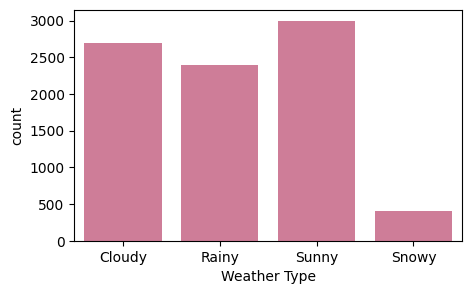

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5, 3)) 
sns.countplot(x = df['Weather Type'] , color="palevioletred")
plt.show()

## Train/test split — done first, before any cleaning

In [8]:
# split the feature and the target :
Features1= df.drop(['Weather Type'], axis=1)  
Target1 = df['Weather Type']      

In [9]:
# seperate the sample to train and test 
from sklearn.model_selection import train_test_split
Xtrain, Xtest, Ytrain, Ytest = train_test_split(Features1, Target1, test_size=0.25, random_state=43)

## Clean only the training fold
Duplicates, missing values (forward-fill), and IQR-based outlier removal are computed and applied to `Xtrain` only. `Xtest` only gets the same missing-value fill (a legitimate, row-independent transform) — it keeps its duplicates and outliers, since that's what real unseen data looks like.

In [10]:
# check the duplicates and missing values 
print(Xtrain.duplicated().sum())
print(Xtrain.isnull().sum())

189
Temperature              0
Humidity                 0
Wind Speed               0
Precipitation (%)        0
Cloud Cover             61
Atmospheric Pressure     0
UV Index                65
Season                   0
Visibility (km)          0
Location                 0
dtype: int64


In [11]:
Xtrain = Xtrain.drop_duplicates()
Ytrain = Ytrain.loc[Xtrain.index]

Xtrain = Xtrain.ffill()
Ytrain = Ytrain.ffill()
Xtest = Xtest.ffill()

In [12]:
# define the numerical and categorical features
numCols = ['Temperature', 'Humidity', 'Wind Speed','Precipitation (%)','Atmospheric Pressure','UV Index','Visibility (km)']
categCols = ['Cloud Cover', 'Season', 'Location']

In [13]:
#Calculate the first quartile (Q1) and third quartile (Q3) for each numerical column
Q1 = Xtrain[numCols].quantile(0.25)
Q3 = Xtrain[numCols].quantile(0.75)
IQR = Q3 - Q1
# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
# Filter the data
mask = ~((Xtrain[numCols] < lower_bound) | (Xtrain[numCols] > upper_bound)).any(axis=1)
# Drop all rows identified as outliers based on the mask
Xtrain.drop(index=Xtrain.index[~mask], inplace=True)
Ytrain = Ytrain.loc[Xtrain.index]

In [14]:
# Check the number of unique value befor encoding :
for col in categCols:
    print(col, df[col].nunique())

Cloud Cover 4
Season 4
Location 3


## Encode & scale — fit on train, applied to test

In [15]:
# Normalization and encoding
from sklearn.preprocessing import MinMaxScaler

# One-hot encode categorical features
Xtrain = pd.get_dummies(
    Xtrain,
    columns=categCols,
    drop_first=True,
    dtype=int
)

Xtest = pd.get_dummies(
    Xtest,
    columns=categCols,
    drop_first=True,
    dtype=int
)


Xtest = Xtest.reindex(columns=Xtrain.columns, fill_value=0)
# Scale numeric features
scaler = MinMaxScaler()
Xtrain[numCols] = scaler.fit_transform(Xtrain[numCols])
Xtest[numCols] = scaler.transform(Xtest[numCols])

In [16]:
from sklearn.preprocessing import LabelEncoder

# Encode target classes ('Sunny','Rainy','Cloudy','Snowy') into numbers
label_encoder = LabelEncoder()
Ytrain_encoded = label_encoder.fit_transform(Ytrain)
Ytest_encoded = label_encoder.transform(Ytest)

## Balance classes with BorderlineSMOTE — training data only

In [17]:
# Balance the data 
from imblearn.over_sampling import BorderlineSMOTE 

smote = BorderlineSMOTE(random_state=43)

Xtrain_resampled, Ytrain_resampled = smote.fit_resample(
    Xtrain,
    Ytrain_encoded
)

In [18]:
# see the data after balancing : 

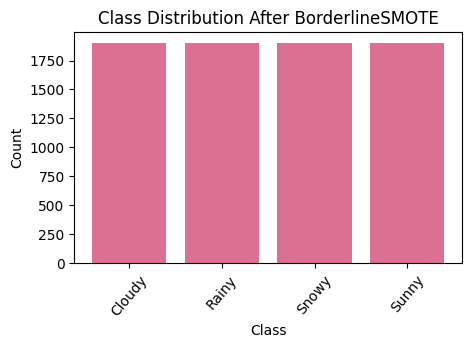

In [19]:
import matplotlib.pyplot as plt

unique, counts = np.unique(Ytrain_resampled, return_counts=True)
labels = label_encoder.inverse_transform(unique)

plt.figure(figsize=(5,3))
plt.bar(labels, counts, color='palevioletred')
plt.title("Class Distribution After BorderlineSMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=50)
plt.show()


In [20]:
Xtrain_resampled

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km),Cloud Cover_cloudy,Cloud Cover_overcast,Cloud Cover_partly cloudy,Season_Spring,Season_Summer,Season_Winter,Location_inland,Location_mountain
0,0.515625,0.056180,0.235294,0.018349,0.777179,0.642857,0.642857,0,0,0,0,1,0,1,0
1,0.781250,0.067416,0.117647,0.036697,0.693180,0.500000,0.607143,0,0,1,0,0,0,0,1
2,0.468750,0.382022,0.235294,0.036697,0.607508,0.785714,0.392857,0,0,0,0,1,0,0,0
3,0.000000,0.730337,0.568627,0.467890,0.283219,0.000000,0.285714,0,1,0,0,0,1,1,0
4,0.046875,0.685393,0.058824,0.486239,0.201821,0.000000,0.071429,0,1,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7603,0.041904,0.798492,0.687459,0.848347,0.136184,0.598849,0.035714,0,1,0,0,0,1,1,0
7604,0.136570,0.576379,0.485676,0.677400,0.116818,0.032279,0.192312,0,0,1,0,0,1,0,1
7605,0.085918,0.797978,0.524767,0.864696,0.075174,0.000000,0.080335,0,0,1,0,0,1,0,1
7606,0.101424,0.619574,0.320456,0.851040,0.073146,0.000000,0.098056,0,0,1,0,0,1,0,1


## Feature selection — SelectKBest + RFE, fit on the resampled training data only

In [21]:
###Feature selection : 

In [22]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE,chi2 
from sklearn.linear_model import LogisticRegression
import pandas as pd
# Use f_classif since the most important features like temperature are numerical and continuous
# f_classif evaluates the correlation between each feature and the target
Kselector = SelectKBest(score_func=f_classif, k=13)
X_kbest = Kselector.fit_transform(Xtrain_resampled, Ytrain_resampled)
# Boolean mask of selected features
kbestFeatures = Kselector.get_support()
# Get the selected feature names
selected_features_kbest = Xtrain_resampled.columns[kbestFeatures]
print("Top 13 features from SelectKBest:" ,list(selected_features_kbest) )
# 2. RFE using LogisticRegression as the estimator
LRselector = LogisticRegression(max_iter=700) 
# Apply RFE to reduce features to top 11
RFEselector = RFE(estimator=LRselector, n_features_to_select=11)
# Fit on features selected by SelectKBest
selected_features_kbestDF = Xtrain_resampled[selected_features_kbest]
X_rfe = RFEselector.fit_transform(selected_features_kbestDF, Ytrain_resampled)
# Boolean mask from RFE
mask_rfe = RFEselector.get_support()
# Final selected features after RFE
final_selected_features = selected_features_kbest[mask_rfe]
print("\nFinal top 11 features after RFE:\n" , list(final_selected_features))


Top 13 features from SelectKBest: ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)', 'Cloud Cover_overcast', 'Cloud Cover_partly cloudy', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'Location_mountain']

Final top 11 features after RFE:
 ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)', 'Cloud Cover_overcast', 'Cloud Cover_partly cloudy', 'Season_Winter', 'Location_mountain']


## Train & evaluate models on the test set

In [23]:
###Train and Evaluat machine learning algorithms

In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [25]:
from sklearn.neural_network import MLPClassifier

MLP_model = MLPClassifier(solver="sgd" , alpha=1e-5 , hidden_layer_sizes=(64,32) ,max_iter=2000, random_state=43)

MLP_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
MLP_pred = MLP_model.predict(Xtest[final_selected_features])
print("\nMLP test accuracy:", accuracy_score(Ytest_encoded, MLP_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, MLP_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Ytest_encoded, MLP_pred))


MLP test accuracy: 0.8927058823529411

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.86      0.89       655
           1       0.91      0.90      0.91       581
           2       0.61      0.90      0.73       119
           3       0.92      0.91      0.92       770

    accuracy                           0.89      2125
   macro avg       0.84      0.89      0.86      2125
weighted avg       0.90      0.89      0.89      2125


Confusion Matrix:
 [[561  41  23  30]
 [ 15 525  19  22]
 [  3   1 107   8]
 [ 29  12  25 704]]


In [26]:
from sklearn.linear_model import SGDClassifier
# Create an SGD Classifier
SGD_model = SGDClassifier(alpha=0.0001 , eta0=1.0,learning_rate="adaptive" ,loss="log_loss",max_iter=1000 ,penalty="l1" , )
SGD_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
SGD_pred = SGD_model.predict(Xtest[final_selected_features])
print("\nSGD test accuracy:", accuracy_score(Ytest_encoded, SGD_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, SGD_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Ytest_encoded, SGD_pred))


SGD test accuracy: 0.8592941176470589

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.82      0.85       655
           1       0.86      0.87      0.86       581
           2       0.58      0.90      0.71       119
           3       0.91      0.88      0.90       770

    accuracy                           0.86      2125
   macro avg       0.81      0.87      0.83      2125
weighted avg       0.87      0.86      0.86      2125


Confusion Matrix:
 [[536  57  27  35]
 [ 30 504  25  22]
 [  3   1 107   8]
 [ 40  26  25 679]]


In [27]:
from sklearn.linear_model import LogisticRegression
LR_model = LogisticRegression(max_iter=1000, random_state=43)
LR_model.fit( Xtrain_resampled[final_selected_features], Ytrain_resampled)
LR_pred = LR_model.predict(Xtest[final_selected_features])
print("\nLogistic Regression test accuracy:", accuracy_score(Ytest_encoded, LR_pred))
print("\nClassification Report:\n" , classification_report(Ytest_encoded, LR_pred))
LRCM=confusion_matrix(Ytest_encoded, LR_pred)
print("\nConfusion Matrix:\n", LRCM)



Logistic Regression test accuracy: 0.8809411764705882

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.85      0.89       655
           1       0.89      0.89      0.89       581
           2       0.56      0.90      0.69       119
           3       0.92      0.90      0.91       770

    accuracy                           0.88      2125
   macro avg       0.82      0.88      0.84      2125
weighted avg       0.89      0.88      0.88      2125


Confusion Matrix:
 [[556  42  26  31]
 [ 12 518  29  22]
 [  3   1 107   8]
 [ 29  22  28 691]]


In [28]:
from sklearn.ensemble import RandomForestClassifier
RF_model = RandomForestClassifier(
    n_estimators=200,  #number of trees in the forest
    max_depth=8,   
    random_state=43,
    min_samples_split=10,
    n_jobs=-1 )  

RFcv = StratifiedKFold(n_splits=8, shuffle=True, random_state=43)
# use ross Cross validation to evaluate the classifier
cv_scores = cross_val_score(
    RF_model,
    Xtrain_resampled[final_selected_features],
    Ytrain_resampled,
    cv=RFcv)

print("Cross-validation scores:\n", cv_scores)
RF_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
RF_pred = RF_model.predict(Xtest[final_selected_features])
print("\nRandomForest test accuracy:", accuracy_score(Ytest_encoded, RF_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, RF_pred))
RFCM=confusion_matrix(Ytest_encoded, RF_pred)
print("\nConfusion Matrix:\n", RFCM)

Cross-validation scores:
 [0.97686646 0.97476341 0.97266036 0.97896951 0.97791798 0.97371188
 0.97896951 0.98633018]

RandomForest test accuracy: 0.9068235294117647

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.92      0.88       655
           1       0.92      0.91      0.91       581
           2       0.88      0.88      0.88       119
           3       0.96      0.90      0.93       770

    accuracy                           0.91      2125
   macro avg       0.90      0.90      0.90      2125
weighted avg       0.91      0.91      0.91      2125


Confusion Matrix:
 [[603  31   5  16]
 [ 40 528   6   7]
 [  6   1 105   7]
 [ 59  16   4 691]]


## Diagnostics: PR curves, ROC curves, overfitting check, confusion matrix, feature importance

In [29]:
#Compare the pr curve between higher accurcy model rf and the worst one sgd

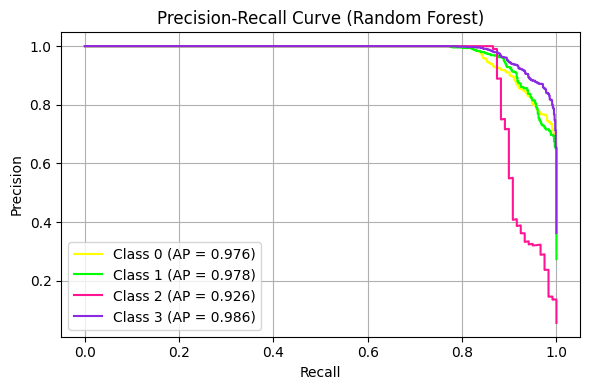

In [30]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
# Get predicted probabilities
RF_probs = RF_model.predict_proba(Xtest[final_selected_features])

# Binarize the target test data 
n_classes = RF_probs.shape[1]
Ytest_bin = label_binarize(Ytest_encoded, classes=list(range(n_classes)))
precision = {} 
recall = {} 
avg_precision = {}

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(Ytest_bin[:, i], RF_probs[:, i])
    avg_precision[i] = average_precision_score(Ytest_bin[:, i], RF_probs[:, i])

plt.figure(figsize=(6, 4))
colors = ['yellow', 'lime', 'deeppink', 'blueviolet']
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i], color=color,
             label=f'Class {i} (AP = {avg_precision[i]:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Random Forest)')
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()


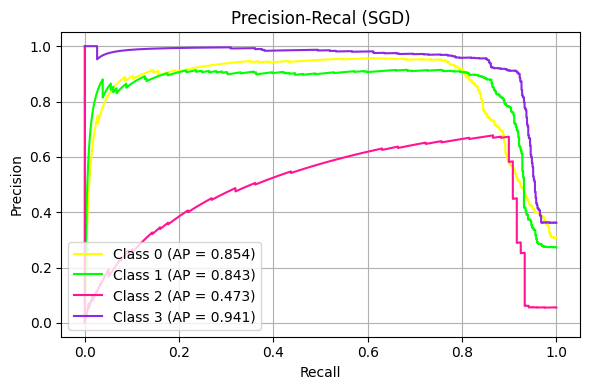

In [31]:
SGD_probs = SGD_model.predict_proba(Xtest[final_selected_features])  
n_classes = SGD_probs.shape[1]
Ytest_bin = label_binarize(Ytest_encoded, classes=list(range(n_classes)))
precision = {}
recall = {}
avg_precision = {}

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(Ytest_bin[:, i], SGD_probs[:, i])
    avg_precision[i] = average_precision_score(Ytest_bin[:, i], SGD_probs[:, i])


plt.figure(figsize=(6, 4))
colors = ['yellow', 'lime', 'deeppink', 'blueviolet']
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i], color=color,
             label=f'Class {i} (AP = {avg_precision[i]:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recal (SGD)')
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()


In [32]:
#compare Random Forest and Logistic Regression using One-vs-Rest ROC curves: 

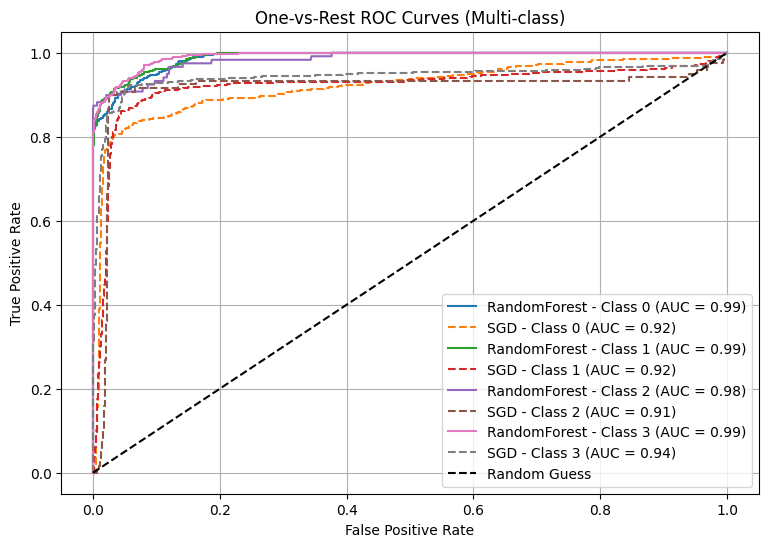

In [33]:
from sklearn.metrics import roc_curve, auc
from sklearn.multiclass import OneVsRestClassifier
# Binarize the labels for multi-class ROC
Ytest_binarized = label_binarize(Ytest_encoded, classes=[0, 1, 2, 3])
n_classes = Ytest_binarized.shape[1]
# Predict probabilities
rf_probs = RF_model.predict_proba(Xtest[final_selected_features])
sgd_probs = SGD_model.predict_proba(Xtest[final_selected_features])
# Plot ROC curve for each class
plt.figure(figsize=(9, 6))
for i in range(n_classes):
    fpr_rf, tpr_rf, _ = roc_curve(Ytest_binarized[:, i], rf_probs[:, i])
    auc_rf = auc(fpr_rf, tpr_rf)
    plt.plot(fpr_rf, tpr_rf, label=f'RandomForest - Class {i} (AUC = {auc_rf:.2f})')

    fpr_sgd, tpr_sgd, _ = roc_curve(Ytest_binarized[:, i], sgd_probs[:, i])
    auc_sgd = auc(fpr_sgd, tpr_sgd)
    plt.plot(fpr_sgd, tpr_sgd, linestyle='--', label=f'SGD - Class {i} (AUC = {auc_sgd:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves (Multi-class)')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
RFtrain_preds = RF_model.predict(Xtrain_resampled[final_selected_features])
RFtrain_acc = accuracy_score(Ytrain_resampled, RFtrain_preds)
print(f"Train Accuracy: {RFtrain_acc:.4f}")

Train Accuracy: 0.9859


In [35]:
# check the confusion_matrix:

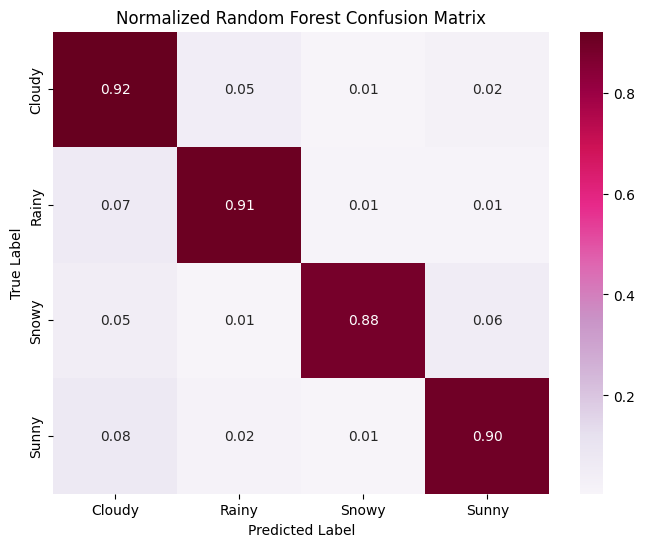

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

classes = ['Cloudy', 'Rainy', 'Snowy', 'Sunny']
cm_norm = RFCM.astype('float') / RFCM.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="PuRd", xticklabels=classes, yticklabels=classes)
plt.title("Normalized Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [37]:
# Shows which features the model relies on the most to explain which features are the most predictive.

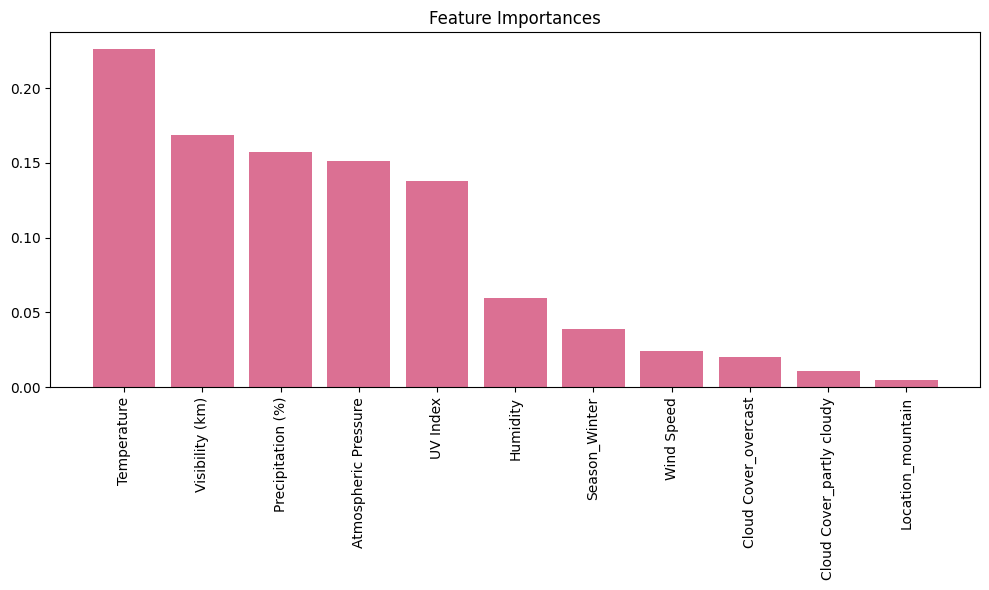

In [38]:
importances = RF_model.feature_importances_
indices = np.argsort(importances)[::-1]
features = Xtrain_resampled[final_selected_features].columns

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(len(importances)), importances[indices],color='palevioletred')
plt.xticks(range(len(importances)), [features[i] for i in indices], rotation=90)
plt.tight_layout()
plt.show()
